# Football Managerial Decision Analytics — Chapter 00
## Project, research design and methodology

> **Data.** StatsBomb Open Data (https://github.com/hudl/open-data), provided by StatsBomb / Hudl, used for educational, non-commercial research. Raw data are downloaded from the official repository at run time and are not redistributed here. Every figure carries its chart ID from `docs/VISUALIZATION_CATALOGUE.md`.

This notebook is one chapter of the research record. All logic lives in the shared `src/` package; the cells call it. The same charts are available interactively in the Streamlit dashboard (`streamlit run app.py`).

In [1]:
# Setup — locate (or fetch) the project code, import the shared package, load the workspace
import os, subprocess, sys, time
from pathlib import Path

REPO_URL = "https://github.com/blazingarrows1525/football-managerial-decision-analytics"
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "workspace.py").exists()), None)
if ROOT is None:  # opened on its own (e.g. Google Colab): fetch the project code once, next to this notebook
    ROOT = Path.cwd() / "football-managerial-decision-analytics"
    if not (ROOT / "src" / "workspace.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("FMA_PROJECT_ROOT", str(ROOT))  # data cache and outputs live inside the project folder

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src.reporting.notebook_tools import (catalogue, explorer, implication, interpret, limitation, show, start,
                                          timed, timings)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:.3f}".format)
RUN_ADVANCED_GALLERY = True   # heavier, optional sections; the core story does not depend on them
SEED = 42                             # every resampling and model step takes this seed explicitly

ws = start(seed=SEED)                 # first run downloads and parses; later runs read the processed cache
B, T, FOCUS = ws.bundle, ws.tables, ws.focus
tm = ws.team_matches()                # the focus team's matches in date order
print(f"Advanced sections: {'on' if RUN_ADVANCED_GALLERY else 'off'} · Python {sys.version.split()[0]} · pandas {pd.__version__}")

**Workspace ready in 3.4s** (processed cache) · 1. Bundesliga 2023/2024 · 34 matches · 137,765 events · focus team **Bayer Leverkusen** · figures: static PNG (FMA_STATIC=1) · seed 42

Advanced sections: on · Python 3.10.11 · pandas 2.1.4


## A · Problem, objectives and scope

**Research question → data and method → chart → interpretation → managerial implication and limitation.**
Every chapter follows this sequence.

### Core question
How can real football event, lineup, player and match-state data be transformed into transparent and
interactive evidence to support starting-XI selection, role fit, tactical interpretation, substitution choices,
rotation analysis and the evaluation of observable managerial decisions?

The system is **decision support, not an oracle**: it states uncertainty and data limits and never claims that
a chart proves a tactical cause or a manager's quality.

### Objectives
1. Build a reproducible pipeline from the published source files to validated analytical tables.
2. Define every metric with its formula, denominator and caveat, and reuse the same definitions in the
   notebooks and in the dashboard.
3. Answer eight research questions with charts that state their sample and their limits.
4. Provide two transparent decision-support tools (starting XI, substitutions) and compare them with what
   actually happened.
5. Quantify uncertainty: effect sizes, bootstrap intervals, false-discovery control, statistical power.
6. Fit a predictive model only where the sample supports it, against a naive baseline, without leakage.

### Hypotheses (stated before looking at the results; each is tested in the chapter named)

| # | Hypothesis | Where tested | How |
|---|---|---|---|
| H1 | Chance quality for and against is more strongly associated with goal difference than possession is | 05 | Spearman ρ with bootstrap CI and FDR control |
| H2 | Results ran ahead of shot-based expectation | 02 | points vs simulated expected points |
| H3 | Chance creation is concentrated in a few players | 02 | cumulative share and Gini of xG + xA |
| H4 | Build-up runs through a small number of hub players | 03 | PageRank and betweenness on pass networks |
| H5 | Past selection explains most starting decisions | 05 | time-ordered cross-validation against a baseline rule |
| H6 | Substitution timing differs by score state | 04 | timing distributions by state (descriptive) |

A hypothesis that the data cannot decide is reported as undecided, not as confirmed.

In [2]:
# Scope of the loaded data — computed, not typed in
m = T["matches"]
scope = pd.DataFrame([
    ("Competition / season", f"{m.competition_name.iloc[0]} {m.season_name.iloc[0]} (competition {B.config.competition_id}, season {B.config.season_id})"),
    ("Matches analysed / published", f"{len(m)} / {B.matches_available}"),
    ("Date range", f"{m.match_date.min():%d %b %Y} – {m.match_date.max():%d %b %Y}"),
    ("Teams / players in match-day squads", f"{B.team_stats.team_name.nunique()} / {T['appearances'].player_id.nunique()}"),
    ("Events", f"{len(T['events']):,}"),
    ("Focus team and its matches", f"{FOCUS} · {len(tm)}"),
    ("Raw files / size", f"{len(B.manifest)} / {B.manifest.bytes.sum() / 1e6:.1f} MB"),
    ("Domain rules passed", f"{int((B.quality.status == 'PASS').sum())}/{len(B.quality)}"),
], columns=["item", "value"])
display(scope)
others = B.team_stats[B.team_stats.team_name != FOCUS].groupby("team_name").match_id.nunique()
times = f"{others.min()}" if others.min() == others.max() else f"{others.min()}–{others.max()}"
interpret(f"Every analysed match involves {FOCUS}; the other {len(others)} teams appear {times} times each. The sample is **team-centric**: it supports statements about {FOCUS} in these matches and "
          f"does not describe the league.")

,item,value
0,Competition / season,"1. Bundesliga 2023/2024 (competition 9, season..."
1,Matches analysed / published,34 / 34
2,Date range,19 Aug 2023 – 18 May 2024
3,Teams / players in match-day squads,18 / 460
4,Events,"137,765"
5,Focus team and its matches,Bayer Leverkusen · 34
6,Raw files / size,70 / 120.1 MB
7,Domain rules passed,16/16


**Interpretation.** Every analysed match involves Bayer Leverkusen; the other 17 teams appear 2 times each. The sample is **team-centric**: it supports statements about Bayer Leverkusen in these matches and does not describe the league.

## Methodology

```
StatsBomb Open Data (JSON over HTTPS)                src/data/statsbomb_client.py   cached, hashed, retried
        │
        ▼
canonical tables: matches · managers · squads · events            src/data/parsers.py + validators.py
        │   minutes reconstructed from Starting XI / Substitution / sending-off events
        ▼
feature tables: event flags · player match & season (per 90, role percentiles) · team match stats
        │                                                         src/features/*
        ▼
analytics: descriptive · statistics · uncertainty · clustering · models · XI and substitution heuristics
        │                                                         src/analytics/*
        ▼
chart registry (one renderer + prerequisites + status per chart)  src/visualization/*
        │
        ├── research notebooks (this folder)        └── Streamlit dashboard (app.py, pages/)
```

**Scale.** About 138 thousand events from one club-season: event-level sports analytics on a single machine.
pandas is the right tool at this volume; no distributed engine is used or claimed. The per-match file layout
would map directly onto a distributed map step if many seasons were added.

**What is not in the data** and is therefore never analysed: player age, height, injuries, fitness or GPS
load, optical tracking, post-shot xG, attendance, weather, market value. Chapter 01 verifies this from the
tables.

In [3]:
# The chart catalogue: what exists, what is available for this data, and why some entries are not
cat = catalogue(ws)
display(cat.groupby(["category", "status"]).size().unstack(fill_value=0))
display(cat[cat.status != "implemented_and_available"][["chart_id", "name", "status", "reason"]])
n_ok = int((cat.status == "implemented_and_available").sum())
interpret(f"{n_ok} of {len(cat)} catalogue entries have a renderer whose prerequisites are met by the loaded data. "
          f"The rest are listed with the reason — an unsupported data modality (tracking), an optional file that "
          f"is not downloaded (360 frames), or no legitimate target. Nothing is filled in to make a chart possible.")

status,implemented_and_available,not_implemented
category,,
Additional project charts and composite dashboards,34,0
Data audit and coverage,16,0
Descriptive and distribution analytics,22,1
Machine learning and diagnostic plots,23,1
Managerial intelligence,13,0
Match and team analysis,27,0
Passing networks and team structure,12,0
"Pitch, spatial and event analytics",25,3
Player performance and scouting,42,0


,chart_id,name,status,reason
37,B-038,Bullet chart: target versus actual,not_implemented,No legitimate external target exists in the da...
125,E-126,Voronoi diagram,not_implemented,Needs every player's position at the same inst...
126,E-127,Delaunay triangulation,not_implemented,Needs simultaneous positions of all team-mates...
127,E-128,Pitch-control / space-control map,not_implemented,Needs positions and velocities of all 22 playe...
243,K-244,Forecast residuals,not_implemented,Forecasting is not justified: 34 matches of on...


**Interpretation.** 273 of 278 catalogue entries have a renderer whose prerequisites are met by the loaded data. The rest are listed with the reason — an unsupported data modality (tracking), an optional file that is not downloaded (360 frames), or no legitimate target. Nothing is filled in to make a chart possible.

**Chart explorer (static fallback).** Live controls appear when the notebook is run interactively with ipywidgets. The catalogue holds 278 entries: 273 implemented and available, 0 implemented but unavailable, 5 not implemented, 0 failed validation. Call `show("<chart_id>", ws)` to render any available chart; `C-042` is shown below.

,chart_id,name,category,status,reason,library,estimated_cost,params,research_question
0,A-001,Dataset composition by table,Data audit and coverage,implemented_and_available,,plotly,low,,How large is each table and which ones come st...
1,A-002,"Row counts by match, team and player",Data audit and coverage,implemented_and_available,,plotly,low,,Is the event volume balanced across matches?
2,A-003,Missingness by field,Data audit and coverage,implemented_and_available,,plotly,low,,Which fields have gaps and how large are they?
3,A-004,Missingness matrix,Data audit and coverage,implemented_and_available,,plotly,low,,Do gaps cluster in particular rows or fields?
4,A-005,Missingness by event type,Data audit and coverage,implemented_and_available,,plotly,low,,Is a missing value expected for that kind of e...
5,A-006,Duplicate full-row and primary-key counts,Data audit and coverage,implemented_and_available,,plotly,medium,,Are there duplicated records or keys?
6,A-007,Duplicate-ID investigation table,Data audit and coverage,implemented_and_available,,plotly,medium,,Which key defines uniqueness in each table?
7,A-008,Numeric field distributions,Data audit and coverage,implemented_and_available,,plotly,low,,What shape do the numeric event fields have?
8,A-009,Categorical frequency and rare categories,Data audit and coverage,implemented_and_available,,plotly,low,,Which categories dominate and which are rare?
9,A-010,Outlier distributions,Data audit and coverage,implemented_and_available,,plotly,low,,Are extreme values errors or real events?


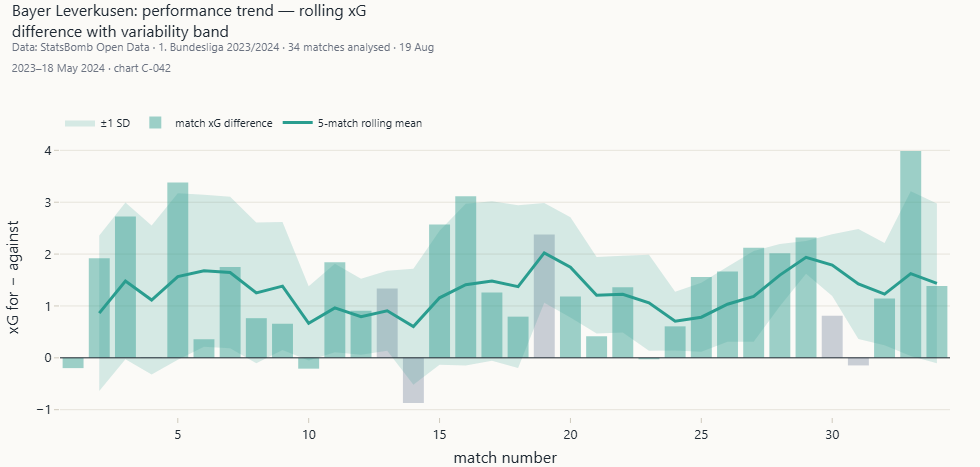

`C-042` Rolling performance form · *Method:* 5-match rolling xG difference with a ±1 SD band.

In [4]:
# Chart explorer: search the catalogue and render one chart on demand.
# With ipywidgets in a live kernel this shows controls; in a headless run it shows the table and one example.
explorer(ws, default="C-042")

## Reproducibility

- `pip install -r requirements.txt`, then run any notebook top to bottom in a fresh kernel.
- `python scripts/run_notebooks.py` executes all of them and writes an execution report.
- Seeds are explicit (`SEED = 42`); the global NumPy generator is never seeded.
- Warnings are not suppressed globally.
- The committed copies were executed with `FMA_STATIC=1`, which stores figures as static images so they are
  visible on GitHub; without it the same cells produce interactive Plotly figures.

In [5]:
from src.reporting.report_builder import environment
display(pd.DataFrame(list(environment().items()), columns=["component", "version"]))
display(timings())

,component,version
0,python,3.10.11
1,platform,Windows-10-10.0.26300-SP0
2,pandas,2.1.4
3,numpy,1.26.2
4,scipy,1.15.3
5,sklearn,1.3.2
6,plotly,6.6.0
7,matplotlib,3.10.8
8,seaborn,0.13.2
9,networkx,3.4.2


,step,seconds
0,load workspace,3.370
1,chart C-042,2.420
